# H4.1 · Perfiles municipales de conectividad en La Paz

**¿Qué municipios se parecen en la proporción de viviendas con Internet fijo y móvil?** El EDA mide ambos accesos y H3.3 predice el porcentaje municipal con algún acceso. Aquí agrupamos municipios a partir de las dos modalidades observadas en el Censo 2024. Cada municipio tiene el mismo peso.

El ejercicio de iFood construye variables por cliente, las estandariza, compara de 2 a 10 grupos con inercia y silueta y adopta cuatro para describir sus clientes. Conservamos esa secuencia y elegimos el número de perfiles con la silueta de los municipios paceños. [Notebook de referencia de Enrique Alejandro Laurel Cossio](https://github.com/ealaurel/MINERIA_DATOS_2026_2/blob/eeabb94b211dcc725d7dadea98328f4671c2a4a2/h4_1_kmeans_ifood.ipynb)

## 1. Recuperar los indicadores del EDA

Usamos `outputs/tablas/municipios.csv`, incluido en el clon. Para cada modalidad, el EDA divide las viviendas que declaran acceso entre todas las viviendas del universo TIC municipal, incluidas las respuestas sin especificar. Una vivienda puede declarar ambas modalidades. Conservamos `pct_algun` para interpretar los grupos al final.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_samples, silhouette_score
from sklearn.preprocessing import StandardScaler

raiz = Path.cwd()
if raiz.name == "notebooks":
    raiz = raiz.parent
ruta = raiz / "outputs" / "tablas" / "municipios.csv"
variables = ["pct_fijo", "pct_movil"]
municipios = pd.read_csv(ruta, dtype={"municipio_codigo": "string"})
municipios = municipios.sort_values("municipio_codigo").reset_index(drop=True)

if municipios["municipio_codigo"].isna().any() or municipios["municipio_codigo"].duplicated().any():
    raise ValueError("Se requiere una fila identificada por municipio.")
tasas = municipios[variables + ["pct_algun"]]
if tasas.isna().any().any() or not tasas.apply(lambda s: s.between(0, 100)).all().all():
    raise ValueError("Hay porcentajes faltantes o fuera del intervalo de 0 a 100.")

print(f"{len(municipios)} municipios · {municipios['universo'].sum():,} viviendas del universo TIC")
display(tasas.describe().round(2))

87 municipios · 1,069,838 viviendas del universo TIC


,pct_fijo,pct_movil,pct_algun
count,87.00,87.00,87.00
mean,5.33,47.98,49.39
std,9.95,10.66,12.00
min,0.31,23.93,24.33
25%,1.05,40.40,40.91
50%,2.45,47.67,48.23
75%,5.07,53.71,56.28
max,70.21,78.06,89.84


## 2. Comparar el número de grupos

Aunque ambas variables se expresan en porcentajes, sus dispersiones pueden diferir. Al estandarizarlas, una desviación típica del acceso fijo pesa tanto como una del móvil. K-Means asigna cada municipio al centroide más cercano y recalcula los centroides hasta que las asignaciones se estabilizan o se alcanza el límite de iteraciones.

La **inercia** mide la dispersión dentro de los grupos. La curva del codo permite ver cuándo añadir grupos aporta cada vez menos. La **silueta** compara la cohesión de un grupo con su separación del grupo vecino. Elegimos el mayor promedio de silueta entre los valores evaluados, con preferencia por el menor *k* en caso de empate. Mostramos también el tamaño del grupo más pequeño para detectar divisiones que aíslan pocos municipios.

In [2]:
escala = StandardScaler()
X = escala.fit_transform(municipios[variables])
max_k = min(10, len(X) - 1, municipios[variables].drop_duplicates().shape[0])
if max_k < 2:
    raise ValueError("Se necesitan al menos tres municipios y dos perfiles distintos.")

modelos = {}
filas = []
for k in range(2, max_k + 1):
    modelo = KMeans(n_clusters=k, init="k-means++", n_init=10, random_state=42).fit(X)
    modelos[k] = modelo
    filas.append({
        "k": k,
        "inercia": modelo.inertia_,
        "silueta": silhouette_score(X, modelo.labels_),
        "menor_grupo": np.bincount(modelo.labels_).min(),
    })

evaluacion = pd.DataFrame(filas).set_index("k")
k_elegido = int(evaluacion["silueta"].idxmax())
final = modelos[k_elegido]
display(evaluacion.round(4))
print(f"k elegido = {k_elegido} · silueta media = {evaluacion.loc[k_elegido, 'silueta']:.3f}")

,inercia,silueta,menor_grupo
k,,,
2,97.5130,0.7900,2
3,44.7470,0.4751,2
4,27.2684,0.4695,2
5,19.1720,0.4738,2
6,14.8868,0.4133,2
7,12.6493,0.4100,2
8,10.3459,0.4137,1
9,8.0314,0.4404,1
10,6.5242,0.4466,1


k elegido = 2 · silueta media = 0.790


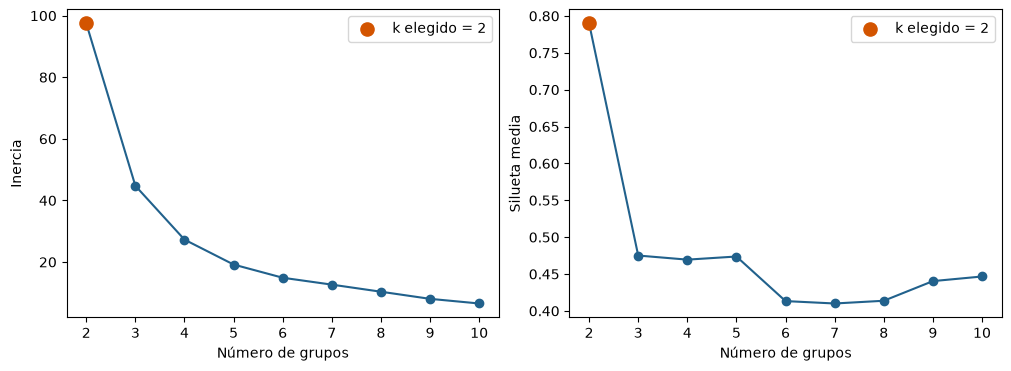

In [3]:
fig, ejes = plt.subplots(1, 2, figsize=(10, 3.6), layout="constrained")
for eje, columna, titulo in zip(ejes, ["inercia", "silueta"], ["Inercia", "Silueta media"]):
    eje.plot(evaluacion.index, evaluacion[columna], "o-", color="#21618c")
    eje.scatter(k_elegido, evaluacion.loc[k_elegido, columna], s=90, color="#d35400",
                label=f"k elegido = {k_elegido}", zorder=3)
    eje.set(xlabel="Número de grupos", ylabel=titulo, xticks=evaluacion.index)
    eje.legend()
plt.show()

## 3. Leer los perfiles en porcentajes

Volvemos a la escala original para ubicar los centroides. Numeramos los perfiles de menor a mayor acceso promedio a algún Internet. Ese indicador se usa solo después del ajuste. Las medias son municipales y cada punto del gráfico representa un municipio. Como ejemplo de cada perfil elegimos el municipio más cercano a su centroide en el espacio estandarizado.

,municipios,pct_fijo,pct_movil,pct_algun,municipio_representativo
perfil,,,,,
1,85,4.04,47.36,48.50,Colquencha
2,2,60.56,74.39,86.98,Nuestra Señora de La Paz


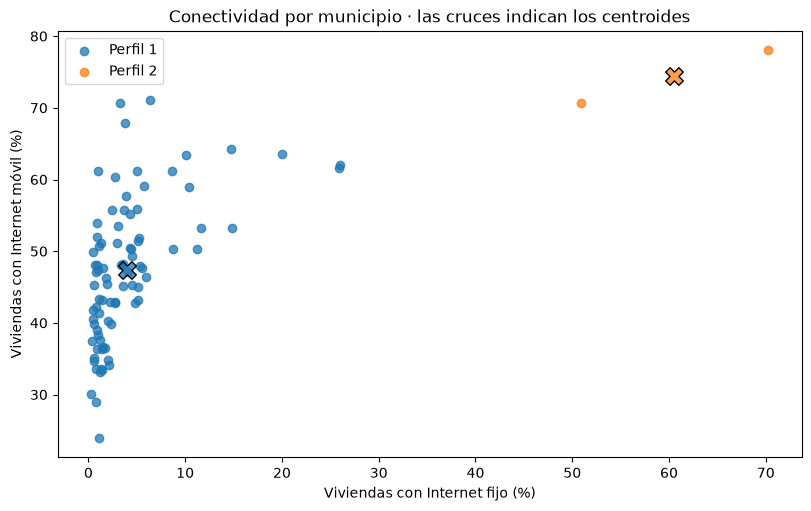

In [4]:
asignaciones = municipios[["municipio_codigo", "municipio", "universo", *variables, "pct_algun"]].copy()
orden = asignaciones.groupby(final.labels_)["pct_algun"].mean().sort_values().index
numeros = {etiqueta: numero for numero, etiqueta in enumerate(orden, start=1)}
asignaciones["perfil"] = pd.Series(final.labels_).map(numeros)
asignaciones["distancia_centroide"] = final.transform(X).min(axis=1)
asignaciones["silueta"] = silhouette_samples(X, final.labels_)

grupos = asignaciones.groupby("perfil")
perfiles = grupos[variables + ["pct_algun"]].mean()
perfiles.insert(0, "municipios", grupos.size())
ejemplos = asignaciones.loc[grupos["distancia_centroide"].idxmin()].set_index("perfil")
perfiles["municipio_representativo"] = ejemplos["municipio"]
display(perfiles.round(2))

centros = pd.DataFrame(escala.inverse_transform(final.cluster_centers_), columns=variables)
centros.index = centros.index.map(numeros)
fig, eje = plt.subplots(figsize=(8, 5), layout="constrained")
for perfil, grupo in grupos:
    puntos = eje.scatter(grupo["pct_fijo"], grupo["pct_movil"], alpha=0.75, label=f"Perfil {perfil}")
    eje.scatter(*centros.loc[perfil, variables], marker="X", s=160,
                color=puntos.get_facecolor()[0], edgecolor="black")
eje.set(xlabel="Viviendas con Internet fijo (%)", ylabel="Viviendas con Internet móvil (%)",
        title="Conectividad por municipio · las cruces indican los centroides")
eje.legend()
plt.show()

## 4. Interpretar la brecha y los casos de frontera

La diferencia en puntos porcentuales entre los perfiles extremos resume la magnitud de la brecha. Una silueta municipal próxima a cero indica que el municipio está cerca de la frontera con otro grupo. Un valor negativo indica que, en promedio, está más cerca de los miembros de otro grupo que de los del suyo.

In [5]:
bajo, alto = perfiles.iloc[0], perfiles.iloc[-1]
for nombre, fila in [("Menor acceso promedio", bajo), ("Mayor acceso promedio", alto)]:
    print(f"{nombre} · {int(fila['municipios'])} municipios · "
          f"{fila['pct_fijo']:.1f}% fijo · {fila['pct_movil']:.1f}% móvil · "
          f"ejemplo: {fila['municipio_representativo']}")
print(f"Brecha media en algún acceso: {alto['pct_algun'] - bajo['pct_algun']:.1f} puntos porcentuales.")
grupo_mayor = grupos.get_group(perfiles["municipios"].idxmax())
print(f"Dentro del perfil más numeroso, el acceso móvil varía de "
      f"{grupo_mayor['pct_movil'].min():.1f}% a {grupo_mayor['pct_movil'].max():.1f}%.")
print("Cinco municipios con la silueta más baja")
display(asignaciones.nsmallest(5, "silueta")[["municipio", "perfil", *variables, "silueta"]].round(3))

Menor acceso promedio · 85 municipios · 4.0% fijo · 47.4% móvil · ejemplo: Colquencha
Mayor acceso promedio · 2 municipios · 60.6% fijo · 74.4% móvil · ejemplo: Nuestra Señora de La Paz
Brecha media en algún acceso: 38.5 puntos porcentuales.
Dentro del perfil más numeroso, el acceso móvil varía de 23.9% a 71.1%.
Cinco municipios con la silueta más baja


,municipio,perfil,pct_fijo,pct_movil,silueta
37,Viacha,1,26.008,62.023,0.254
2,Mecapaca,1,25.916,61.542,0.267
3,Achocalla,1,19.985,63.582,0.442
74,San Buenaventura,1,14.707,64.198,0.563
32,Tipuani,1,6.321,71.107,0.572


En la tabla censal de 2024, El Alto y Nuestra Señora de La Paz forman un perfil de acceso fijo especialmente alto. La silueta favorece esta separación marcada. Los demás municipios comparten el otro perfil y aun así presentan diferencias de acceso móvil, como muestra el rango calculado arriba. Para investigar las causas harían falta datos de infraestructura, precios o cobertura. Las diferencias entre viviendas de un mismo municipio quedan ocultas por la agregación.

## 5. Guardar los resultados

Se exportan la asignación de cada municipio, las medias de cada perfil y la comparación de valores de *k*. Los porcentajes conservan su precisión en los CSV.

In [6]:
salida = raiz / "outputs" / "modelado"
salida.mkdir(parents=True, exist_ok=True)
asignaciones.to_csv(salida / "kmeans_municipios.csv", index=False)
perfiles.to_csv(salida / "kmeans_perfiles.csv")
evaluacion.to_csv(salida / "kmeans_evaluacion.csv")
print("Resultados guardados en outputs/modelado/")

Resultados guardados en outputs/modelado/
